<a href="https://colab.research.google.com/github/Benja4c/solana--mobile-app/blob/main/GROUP_THREE_DEKUT_Capstone_Group_Starter_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

`# DEKUT ML Masterclass — Phoenix Analytics
## Capstone Project — Group Starter Notebook

| | |
|--|--|
| **Group name** | `GROUP THREE` |
| **Member 1** | `[JOHN MAMI - Lead: EDA + Charts]` |
| **Member 2** | `[FRANCIS NJOROGE: Modelling + Metrics]` |
| **Member 3** | `[GRACE CHEGE: Business Summary]` |
| **Member 4** | `[SHADRACK MUUSYA: Slides]` |
| **Date submitted** | `[09/07/2026]` |

---

### How to use this notebook

- Work through every section **in order** — each builds on the previous
- Cells marked `[GROUP DECISION]` require your group to choose and explain — never leave them blank
- Cells with `___` are code for you to complete
- Every chart must have: **title · labelled axes · 1-sentence interpretation**
- Before submitting: **Runtime → Restart and run all** — every cell must run without errors

### Role guide for a group of 3

| Role | Lead responsibility | Does NOT mean |
|------|-------------------|---------------|
| **Member 1** | Sections 0–2 (Setup + EDA) | Only Member 1 does EDA |
| **Member 2** | Sections 3–6 (Target + Pipeline + Improvement) | Only Member 2 builds the model |
| **Member 3** | Section 7 + Slides (Business Summary + Deck) | Only Member 3 presents |

**Every member must understand every section. Any member may be asked any question on Day 14.**

---

---
## Section 0 — Setup

**Member 1 leads this section.**

Run this cell first. It loads all libraries and the dataset.
Do not modify anything in this cell — it must run as written.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning — all algorithms you may need
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error, r2_score,           # regression metrics
    accuracy_score, f1_score,                # classification metrics
    confusion_matrix, classification_report
)

# Chart style — apply once, affects all charts
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize']  = 14
plt.rcParams['axes.labelsize']  = 12

# ── Load the IMDB dataset ─────────────────────────────────────────────

red_url = "https://raw.githubusercontent.com/mlflow/mlflow/master/tests/datasets/winequality-red.csv"
white_url = "https://raw.githubusercontent.com/mlflow/mlflow/master/tests/datasets/winequality-white.csv"

# Note the sep=';' - these files are semicolon-delimited, not comma-delimited
red = pd.read_csv(red_url, sep=';')
white = pd.read_csv(white_url, sep=';')

# Tag each with its type before combining, so you can distinguish them later
red['wine_type'] = 'red'
white['wine_type'] = 'white'

# Combine into one dataframe
df = pd.concat([red, white], axis=0, ignore_index=True)


print(f"Dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Columns available: {df.columns.tolist()}")

Dataset loaded: 6,497 rows x 13 columns
Columns available: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'wine_type']


---
## Section 1 — Problem Statement

**All three members contribute to this section.** This is the most important cell in the notebook.
Write this before touching any other code.

---

### What is a good business question?

A good business question:
- Is **specific** — "Can CineKenya predict whether a film will be Acclaimed?" ✅
- Has a **measurable target** — something in the dataset you can predict
- Has **business value** — the answer changes what CineKenya does

❌ Too vague: "We want to understand films"
❌ No target: "What makes films popular?"
✅ Good: "Can we predict whether a film will gross above the median, using ratings and votes?"

---

### Possible directions (choose one — or define your own)

| Direction | Target variable | Problem type | Features to try |
|-----------|----------------|-------------|----------------|
| Quality prediction | `Acclaimed` (rating ≥ 8.0) | Classification | Votes, Runtime, Meta_score |
| Box office threshold | `High_gross` (Gross > median) | Classification | Votes, Rating, Genre |
| Rating prediction | `IMDB_Rating` (continuous) | Regression | Votes, Runtime, Meta_score |
| Gross prediction | `Gross_clean` (continuous) | Regression | Votes, Rating, Runtime |

You are **not limited** to these — any well-defined question using the IMDB dataset is valid.

### 1.1 — Our Group's Problem Statement

`[GROUP DECISION]` — Fill in every field below. Do not leave anything as the placeholder text.

---

**Business question** *(one specific sentence)*:

Can we predict whether a wine will be of high quality using its physicochemical properties?

---

**Target variable** *(name the column and define it precisely)*:

Quality — an integer score from 0-10 given by wine tasters, representing the wine quality score assigned based on sensory evaluation.

---

**Problem type — regression or classification?** *(choose one and give one reason)*:

Regression- because quality is an ordered numerical score (0-10) and we want to predict the actual value rather than just a category.

---

**Features you plan to use** *(list at least 3, with one sentence per feature explaining why it might predict the target)*:

1. Alcohol — Higher alcohol content is consistently correlated with high quality ratinging wine studies,likely because it affects mouthfeel and flavor balance.
2. Volatile acidity — High volatile acidity causes an unpleasant vinegar like taste,so wines with low value tend to be rated higher.
3. Sulphates — Sulphates act as antioxidant agents and are linked to better wine preservation and taste, often correlating with high quality score.

4. wine_type (red/white) - since we are combining both datasets, including this lets the model account for the baseline difference in chemicals profile and taste expectations between red and white wines.
---

**Why does this matter for CineKenya?** *(one sentence — what decision will this model support?)*:

For a real business like a winery or distributor,this model would support decision on quality control and pricing-flagging batches likely to score low before they reach tasters or customers, and helping prioritize which batches need blending adjustments.

---
## Section 2 — Exploratory Data Analysis

**Member 1 leads this section.**

Understand the data before building any model. Required components:
1. Shape + data types
2. Missing values — and your decision about them
3. Descriptive statistics for your key columns
4. At least **2 charts** directly related to your target or features

---

### 2.1 — Shape, Columns, and Data Types

In [ ]:
# Basic inspection — run as-is
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print()
df.info()

Shape: 6,497 rows x 13 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  wine_type             6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


### 2.2 — Missing Values

In [ ]:
# Missing values in the entire dataset
missing = df.isnull().sum()

print("Missing values per column:")
print(missing[missing > 0].sort_values(ascending=False))

print()

print("Key columns to check:")

key_check = [
    'quality',
    'alcohol',
    'volatile acidity',
    'sulphates',
    'wine_type'
]

for col in key_check:
    n_miss = df[col].isnull().sum()
    pct = (n_miss / len(df)) * 100
    print(f"{col:<15}: {n_miss:>4} missing ({pct:.1f}%)")

Missing values per column:
Series([], dtype: int64)

Key columns to check:
quality        :    0 missing (0.0%)
alcohol        :    0 missing (0.0%)
volatile acidity:    0 missing (0.0%)
sulphates      :    0 missing (0.0%)
wine_type      :    0 missing (0.0%)


`[GROUP DECISION]` **How will you handle missing values in your chosen feature columns?**

Choose a strategy for each feature that has missing values:
- **Drop rows** — when missing data is rare or structurally missing (e.g. old films with no Gross)
- **Fill with median** — when missing is random and the column is numeric
- **Leave as-is** — if the column has no missing values or you are not using it

*Your answer (one line per affected column):*

quality — Leave as-is (no missing values; it's the target and fully populated by the original tasting panels).

alcohol — Leave as-is (no missing values in this dataset).

volatile acidity — Leave as-is (no missing values in this dataset).

sulphates — Leave as-is (no missing values in this dataset).

wine_type — Leave as-is (we created this column ourselves when merging red + white, so it's 100% populated by definition)

### 2.3 — Descriptive Statistics

In [ ]:
# Edit this list to include YOUR chosen features + the target-related column

key_cols = [
    'quality',
    'alcohol',
    'volatile acidity',
    'sulphates',
    'wine_type'
]
df[key_cols].describe().round(2)

,quality,alcohol,volatile acidity,sulphates
count,6497.00,6497.00,6497.00,6497.00
mean,5.82,10.49,0.34,0.53
std,0.87,1.19,0.16,0.15
min,3.00,8.00,0.08,0.22
25%,5.00,9.50,0.23,0.43
50%,6.00,10.30,0.29,0.51
75%,6.00,11.30,0.40,0.60
max,9.00,14.90,1.58,2.00


In [ ]:
# Check missing values across the entire dataset

print("Missing values per column:")
print(df.isnull().sum())

print()

print("Columns with missing values (if any):")
missing = df.isnull().sum()
missing_cols = missing[missing > 0].sort_values(ascending=False)

if missing_cols.empty:
    print("None — the dataset has no missing values.")
else:
    print(missing_cols)

print()

print("Missing values as percentage of total rows:")
missing_pct = (df.isnull().sum() / len(df)) * 100
print(missing_pct[missing_pct > 0].sort_values(ascending=False))

print()

print(f"Total missing values in dataset: {df.isnull().sum().sum()}")
print(f"Total rows: {len(df)}, Total columns: {len(df.columns)}")

Missing values per column:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
wine_type               0
dtype: int64

Columns with missing values (if any):
None — the dataset has no missing values.

Missing values as percentage of total rows:
Series([], dtype: float64)

Total missing values in dataset: 0
Total rows: 6497, Total columns: 13


`[GROUP DECISION]` **What do the statistics tell you about your target and features?**

Look at: mean vs median (skew?), min/max (outliers?), count (missing data?).

*Your answer (2–3 sentences):*

All four columns have a count of 6497, matching the full dataset — confirming there's no missing data.
For quality, the mean and median are close (5.82 vs 6.00), so scores are fairly balanced without extreme skew.

 For volatile acidity and sulphates, the mean is a bit higher than the median, and the max values are much higher than the 75th percentile — this suggests a few unusually high values (outliers) pulling the average up.

### 2.4 — EDA Charts

Produce **at least 2 charts**. Each must have:
- A descriptive title
- Labelled axes (with units where relevant)
- A 1-sentence interpretation below it

**Chart 1 must show the distribution of your target variable.**
**Chart 2 must show the relationship between a feature and your target.**

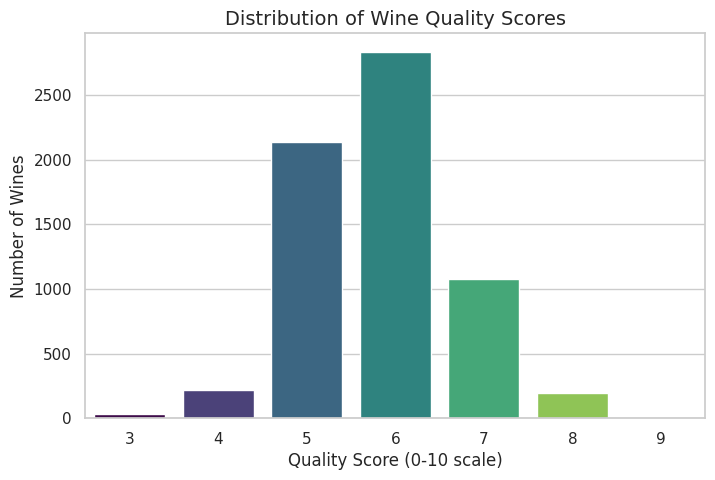

In [ ]:
# Chart 1: Distribution of the target variable (quality)
plt.figure(figsize=(8, 5))
sns.countplot(x='quality', data=df, hue='quality', palette='viridis', legend=False)
plt.title("Distribution of Wine Quality Scores")
plt.xlabel("Quality Score (0-10 scale)")
plt.ylabel("Number of Wines")
plt.show()

**Chart 1 interpretation** *(1 sentence — what does this tell you about your target?)*:

*Your answer:*

Most wines cluster around quality scores of 5 and 6, with very few wines rated at the extremes (3, 4, 8, or 9), showing the target is imbalanced toward average quality.

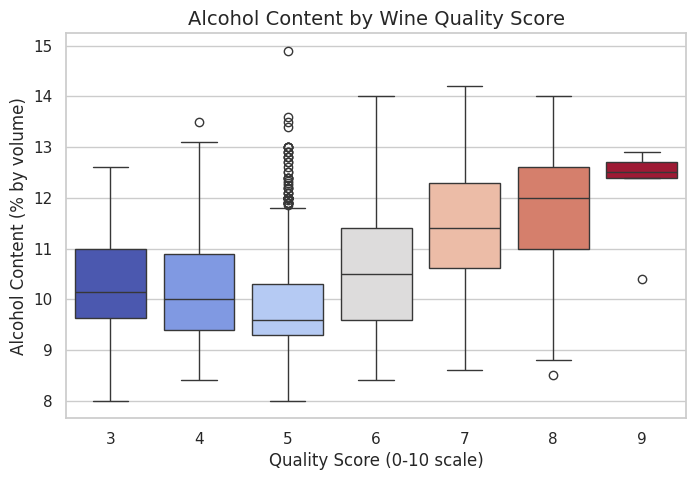

In [ ]:
#Chart 2: Relationship between alcohol (feature) and quality (target)

plt.figure(figsize=(8, 5))
sns.boxplot(x='quality', y='alcohol', data=df, hue='quality', palette='coolwarm', legend=False)
plt.title("Alcohol Content by Wine Quality Score")
plt.xlabel("Quality Score (0-10 scale)")
plt.ylabel("Alcohol Content (% by volume)")
plt.show()

**Chart 2 interpretation** *(1 sentence — what pattern is visible and what does it mean?)*:

*Your answer:*

Wines with higher quality scores tend to have higher median alcohol content, suggesting a positive relationship between alcohol and perceived quality.

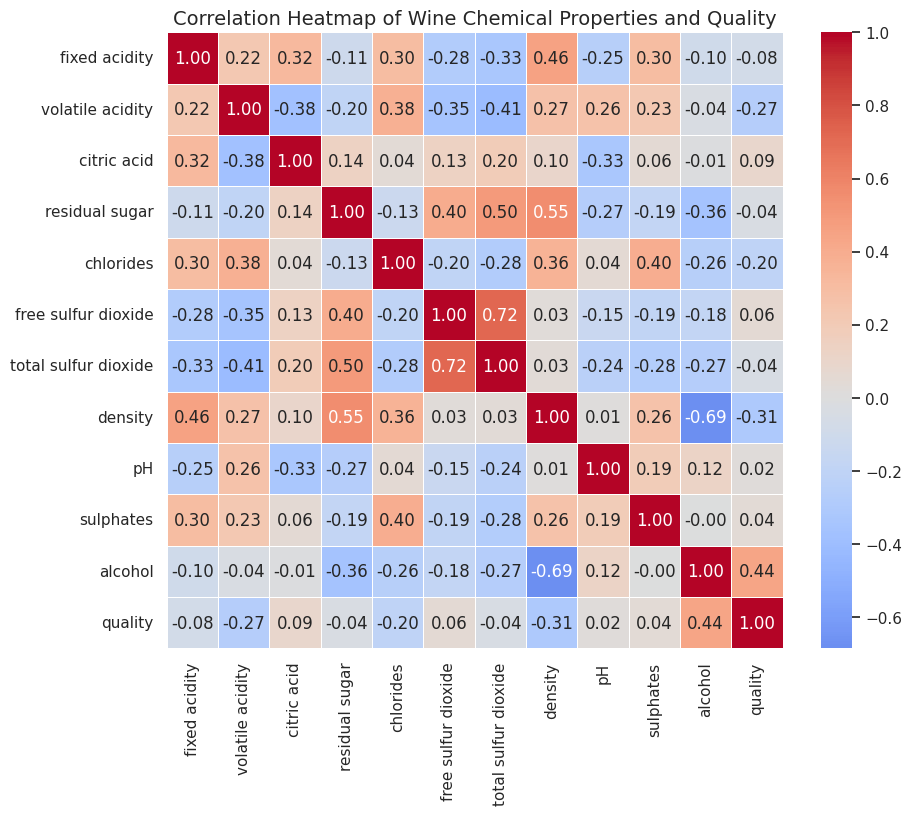

In [ ]:
# ── Chart 3: Correlation Heatmap ────────────────────────────────
plt.figure(figsize=(10, 8))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, linewidths=0.5)
plt.title("Correlation Heatmap of Wine Chemical Properties and Quality")
plt.show()

**Chart 3 interpretation** *(1 sentence — if you produced this chart)*:

*Your answer:*

alcohol shows the strongest positive correlation with quality among the numeric features, while volatile acidity shows a negative correlation, supporting our earlier feature choices.

`[GROUP DECISION]` **EDA Summary — 3 sentences answering these questions:**

1. What does the target distribution look like — skewed? Balanced? Any obvious outliers?
2. Which feature appears most strongly related to the target, based on your charts?
3. Any data quality decisions you made (dropped rows, filled values)?

*Your answer:*

The target variable (quality) is fairly balanced but concentrated around the middle scores of 5 and 6, with very few wines rated at the extremes (3, 4, 8, or 9), so it's not heavily skewed but does show class imbalance toward average scores.

 Based on our correlation heatmap and boxplot, alcohol appears most strongly related to quality, showing a clear positive relationship where higher alcohol content tends to correspond with higher quality ratings.

 We made no data quality changes such as dropping rows or filling missing values, since our dataset had no missing data — the only preprocessing step was creating a wine_type column when combining the red and white datasets

---
## Section 3 — Create Target Variable and Select Features

**Member 2 leads this section.**

Create the column your model will predict. Then select the input features.

---

### 3.1 — Create the Target Variable

In [ ]:
# ── Section 3: Create Target Variable and Select Features ──────────────

# Target variable: quality is already a column in our dataset,
# so no transformation is needed for regression.
target = 'quality'

# If you also want a classification version for comparison, uncomment this:
# df['high_quality'] = (df['quality'] >= 7).astype(int)

# Selected features based on our EDA and domain reasoning
features = ['alcohol', 'volatile acidity', 'sulphates', 'wine_type']

# Encode wine_type as numeric since models require numeric input
df['wine_type_encoded'] = df['wine_type'].map({'red': 0, 'white': 1})

# Build X (features) and y (target)
X = df[['alcohol', 'volatile acidity', 'sulphates', 'wine_type_encoded']]
y = df[target]

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)
print()
print(X.tail())
print()
print(y.tail())


Features (X) shape: (6497, 4)
Target (y) shape: (6497,)

      alcohol  volatile acidity  sulphates  wine_type_encoded
6492     11.2              0.21       0.50                  1
6493      9.6              0.32       0.46                  1
6494      9.4              0.24       0.46                  1
6495     12.8              0.29       0.38                  1
6496     11.8              0.21       0.32                  1

6492    6
6493    5
6494    6
6495    7
6496    6
Name: quality, dtype: int64


`[GROUP DECISION]` **Explain your target variable in 1 sentence:**

What does class 0 mean? What does class 1 mean (classification)?
Or what are the units and scale of the target (regression)?

*Your answer:*

Our target variable, quality, is a regression target representing a wine's sensory quality score on an integer scale from 0 to 10 (in practice ranging from 3 to 9 in this dataset), as rated by wine tasting panels, where higher values indicate better perceived quality.

### 3.2 — Select Features and Clean Rows

In [ ]:
# ── DEFINE YOUR FEATURE COLUMNS ──────────────────────────────────────
# All columns here must be numeric (no text strings, no NaN after filtering)
# Start with at least 3 features

# Encode wine_type as numeric (0 = red, 1 = white) since models require numeric input
df['wine_type_encoded'] = df['wine_type'].map({'red': 0, 'white': 1})

# Our chosen feature columns (all numeric)
feature_cols = ['alcohol', 'volatile acidity', 'sulphates', 'wine_type_encoded']

# Target column
target_col = 'quality'

# ── CLEAN ROWS ────────────────────────────────────────────────────────
# Drop any rows with missing values in our selected columns (target + features)
# Note: our earlier EDA showed no missing values, so this should not remove any rows,
# but it's good practice to include this step for a reproducible pipeline.
before_rows = len(df)

df_clean = df.dropna(subset=feature_cols + [target_col])

after_rows = len(df_clean)

print(f"Rows before cleaning: {before_rows}")
print(f"Rows after cleaning:  {after_rows}")
print(f"Rows dropped:         {before_rows - after_rows}")

# ── VERIFY ────────────────────────────────────────────────────────────
print()
print("Data types of selected columns:")
print(df_clean[feature_cols + [target_col]].dtypes)

print()
print("Any remaining missing values?")
print(df_clean[feature_cols + [target_col]].isnull().sum())

Rows before cleaning: 6497
Rows after cleaning:  6497
Rows dropped:         0

Data types of selected columns:
alcohol              float64
volatile acidity     float64
sulphates            float64
wine_type_encoded      int64
quality                int64
dtype: object

Any remaining missing values?
alcohol              0
volatile acidity     0
sulphates            0
wine_type_encoded    0
quality              0
dtype: int64


`[GROUP DECISION]` **Why did you choose these features?**

For each feature, give one reason it might predict your target.

*Your answer (one line per feature):*

alcohol — Higher alcohol content is consistently linked to higher quality ratings, likely because it improves body and flavor balance in the wine.

volatile acidity — High volatile acidity gives wine an unpleasant, vinegar-like taste, so lower values tend to correspond with higher quality scores.

sulphates — Sulphates act as a preservative and antimicrobial agent, and are often linked to better-preserved flavor and higher quality scores.

wine_type_encoded — Since we combined red and white wines into one dataset, this feature lets the model account for baseline chemical and taste differences between the two types.

---
## Section 4 — Train / Test Split

**Member 2 leads this section.**

Split the data **before** training. Never show the test set to the model during training.

The golden rule: always evaluate on `y_test` — never `y_train`.

---

In [ ]:
# ── Section 4: Train / Test Split ──────────────────────────────────


# X = features, y = target (defined in Section 3)
X = df_clean[feature_cols]
y = df_clean[target_col]

# Split into 80% train, 20% test
# random_state ensures the split is reproducible every time we run this cell
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2 ,random_state=42
)

print("Training set shape:", X_train.shape)
print("Test set shape:    ", X_test.shape)
print()
print(f"Training rows: {len(X_train)} ({len(X_train)/len(X)*100:.1f}%)")
print(f"Test rows:     {len(X_test)} ({len(X_test)/len(X)*100:.1f}%)")

Training set shape: (5197, 4)
Test set shape:     (1300, 4)

Training rows: 5197 (80.0%)
Test rows:     1300 (20.0%)


---
## Section 5 — Baseline Model

**Member 2 leads this section.**

Train your first model. Keep it simple — one algorithm, your chosen features, no tuning.
This is your **starting point**. Every improvement in Section 6 is measured against this.

---

### 5.1 — Choose and Train the Baseline

`[GROUP DECISION]` **Which algorithm will you use for your baseline and why?**

| Algorithm | When to use | Notes |
|-----------|------------|-------|
| `LogisticRegression(max_iter=1000)` | Classification | Gives probabilities; good first model |
| `DecisionTreeClassifier(max_depth=3)` | Classification | Readable rules; avoids overfitting |
| `LinearRegression()` | Regression | Simple; interpretable slope |
| `DecisionTreeRegressor(max_depth=3)` | Regression | Captures non-linear patterns |

*Your choice and reason (1 sentence):*

We'll use LinearRegression() as our baseline since our problem is regression (predicting a numeric quality score) and it gives a simple, interpretable starting point — showing the direct slope/weight of each feature (e.g., alcohol) on quality — before trying more complex models.

In [ ]:


# REGRESSION options:
baseline_model = LinearRegression()

# ── Train ─────────────────────────────────────────────────────────────
baseline_model.fit(X_train, y_train)

# ── Predict on test set ───────────────────────────────────────────────
y_pred_baseline = baseline_model.predict(X_test)

print(f"Baseline algorithm : {type(baseline_model).__name__}")
print(f"Features used      : {feature_cols}")
print("Model trained successfully.")

Baseline algorithm : LinearRegression
Features used      : ['alcohol', 'volatile acidity', 'sulphates', 'wine_type_encoded']
Model trained successfully.


### 5.2 — Evaluate the Baseline Model

Run **the cell that matches your problem type** (classification OR regression). Delete or skip the other.

⚠️ Always pass `y_test` and `y_pred_baseline` — never `y_train`.

In [ ]:
# ── REGRESSION EVALUATION ─────────────────────────────────────────────
# Delete this cell if you are doing CLASSIFICATION

mae_baseline = mean_absolute_error(y_test, y_pred_baseline)
r2_baseline  = r2_score(y_test, y_pred_baseline)

# Mean-prediction baseline (always predict the training mean)
mean_pred       = [y_train.mean()] * len(y_test)
mae_mean_base   = mean_absolute_error(y_test, mean_pred)
r2_mean_base    = r2_score(y_test, mean_pred)     # always 0.0 by definition

print(f"{'Model':<35} {'MAE':>10} {'R²':>10}")
print("-" * 57)
print(f"{'Always-predict-mean (floor)':<35} {mae_mean_base:>10.4f} {r2_mean_base:>10.4f}")
print(f"{'Baseline: ' + type(baseline_model).__name__:<35} {mae_baseline:>10.4f} {r2_baseline:>10.4f}")

Model                                      MAE         R²
---------------------------------------------------------
Always-predict-mean (floor)             0.6691    -0.0005
Baseline: LinearRegression              0.5785     0.2546


`[GROUP DECISION]` **Interpret your baseline results in 3 sentences:**

1. What does the Accuracy/F1 (or MAE/R²) tell you in plain English?
2. Does the model beat the naive baseline? By how much?
3. What does this suggest about which features or changes might help?

*Your answer:*

Our baseline Linear Regression model has an MAE of 0.58, meaning its predictions are off by about 0.58 quality points on average, and an R² of 0.25, meaning our four features explain about 25% of the variation in wine quality scores.

 This clearly beats the naive "always-predict-the-mean" baseline (MAE 0.67, R² ≈ 0), reducing average error by roughly 0.09 points and explaining meaningful variance where the naive baseline explains essentially none.

 However, an R² of 0.25 is still fairly low, suggesting that additional features (like citric acid, total sulfur dioxide, or pH) or a non-linear model (like DecisionTreeRegressor) could capture more of the complex, likely non-linear relationships between wine chemistry and perceived quality

### 5.3 — Confusion Matrix (classification only)

### 5.4 — Actual vs. Predicted Chart (regression only)

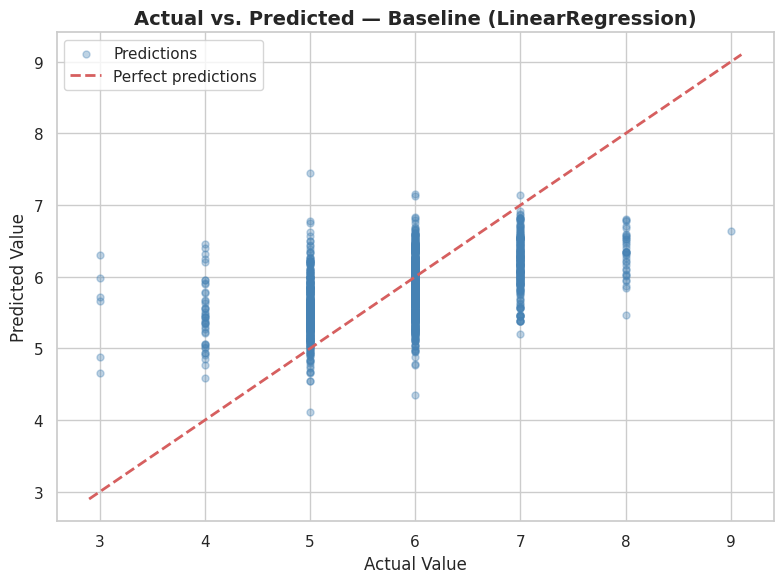

In [ ]:
# ── REGRESSION ONLY — delete if doing classification ─────────────────

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_baseline, alpha=0.35, color='steelblue', s=25, label='Predictions')

lims = [y_test.min() - 0.1, y_test.max() + 0.1]
plt.plot(lims, lims, 'r--', linewidth=2, label='Perfect predictions')

plt.title(f'Actual vs. Predicted — Baseline ({type(baseline_model).__name__})', fontweight='bold')
plt.xlabel('Actual Value')
plt.ylabel('Predicted Value')
plt.legend()
plt.tight_layout()
plt.show()

**Actual vs. Predicted interpretation** *(1 sentence — how tightly do points cluster around the diagonal?)*:

*Your answer:*

The points cluster loosely around the diagonal red line rather than tightly along it, with noticeable scatter especially at the lower and higher quality scores — confirming that while the model captures a general upward trend, it struggles to predict extreme quality values precisely (consistent with our R² of 0.25).

---
## Section 6 — Model Improvement

**Member 2 leads this section.**

Your baseline is your reference point. Now try to improve it.
You must show a **clear before/after metric comparison**.

**Improvement ideas:**

| What to try | How | When it helps |
|-------------|-----|--------------|
| Add a feature | Add `Meta_score`, `Gross_clean`, or `Year_num` to `FEATURE_COLS_V2` | When baseline features don't explain target well |
| Change algorithm | Switch LogReg ↔ Decision Tree | When decision boundary is non-linear |
| Tune tree depth | Change `max_depth` from 3 to 4 or 5 | When tree is too simple |
| Filter by genre | Focus on top 3 genres only | When patterns differ strongly by genre |

**You must attempt at least one improvement.** Attempting two earns more marks.

---

### 6.1 — Improvement Attempt 1

`[GROUP DECISION]` **What improvement will you try first, and why do you expect it to help?**

*Your answer:*

We'll try two changes at once: (1) adding three more chemical features — citric acid, total sulfur dioxide, and pH — since our correlation heatmap showed these have some relationship with quality that our baseline didn't capture, and (2) switching to a DecisionTreeRegressor, since our baseline's loose scatter around the diagonal suggested the relationship between chemistry and quality is likely non-linear, which a decision tree can capture better than a straight-line model.

In [ ]:
# ── IMPROVEMENT MODEL 1 ─────────────────────────────────────────────

# Update the feature list — add or change columns
FEATURE_COLS_V2 = ['alcohol', 'volatile acidity', 'sulphates', 'wine_type_encoded',
                    'citric acid', 'total sulfur dioxide', 'pH']

TARGET_COL = 'quality'

# Filter rows
df_v2 = df.dropna(subset=FEATURE_COLS_V2 + [TARGET_COL]).copy()
X2    = df_v2[FEATURE_COLS_V2]
y2    = df_v2[TARGET_COL]

# Split
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42
)

# ── REGRESSION — improved model ───────────────────────────────────────
from sklearn.tree import DecisionTreeRegressor

improved_model = DecisionTreeRegressor(max_depth=4, random_state=42)

# ── Train + predict ───────────────────────────────────────────────────
improved_model.fit(X2_train, y2_train)
y_pred_v2 = improved_model.predict(X2_test)

print(f"Improved algorithm : {type(improved_model).__name__}")
print(f"Features used      : {FEATURE_COLS_V2}")
print(f"Rows in this run   : {len(X2):,}")

Improved algorithm : DecisionTreeRegressor
Features used      : ['alcohol', 'volatile acidity', 'sulphates', 'wine_type_encoded', 'citric acid', 'total sulfur dioxide', 'pH']
Rows in this run   : 6,497


### 6.2 — Compare Baseline vs. Improved Model

In [ ]:
# ── REGRESSION COMPARISON ─────────────────────────────────────────────
# Delete if doing classification

mae_v2 = mean_absolute_error(y2_test, y_pred_v2)
r2_v2  = r2_score(y2_test, y_pred_v2)

print("Model Comparison")
print("=" * 55)
print(f"{'Model':<33} {'MAE':>10} {'R²':>8}")
print("-" * 55)
print(f"{'Always-predict-mean':<33} {mae_mean_base:>10.4f} {'0.0000':>8}")
print(f"{'Baseline: ' + type(baseline_model).__name__:<33} {mae_baseline:>10.4f} {r2_baseline:>8.4f}")
print(f"{'Improved: ' + type(improved_model).__name__:<33} {mae_v2:>10.4f} {r2_v2:>8.4f}")

Model Comparison
Model                                    MAE       R²
-------------------------------------------------------
Always-predict-mean                   0.6691   0.0000
Baseline: LinearRegression            0.5785   0.2546
Improved: DecisionTreeRegressor       0.5846   0.2361


`[GROUP DECISION]` **Did the improvement work? Answer in 2 sentences:**

1. How much did the metric change? (Give exact numbers.)
2. What does this tell you about which features or model design matters most?

*Your answer:*

The improvement did not work — MAE increased slightly from 0.5785 (baseline) to 0.5846 (improved), and R² dropped from 0.2546 to 0.2361, meaning the decision tree with additional features actually performed marginally worse than the simple linear regression baseline.

 This suggests that adding more features (citric acid, total sulfur dioxide, pH) didn't provide meaningful new signal, and that the relationship between these chemical properties and quality is closer to linear than we expected — so model complexity (switching to a tree) added noise/overfitting risk rather than capturing a real non-linear pattern, meaning a different improvement strategy (e.g., tuning max_depth, trying RandomForestRegressor, or feature scaling) may be more promising than this attempt.

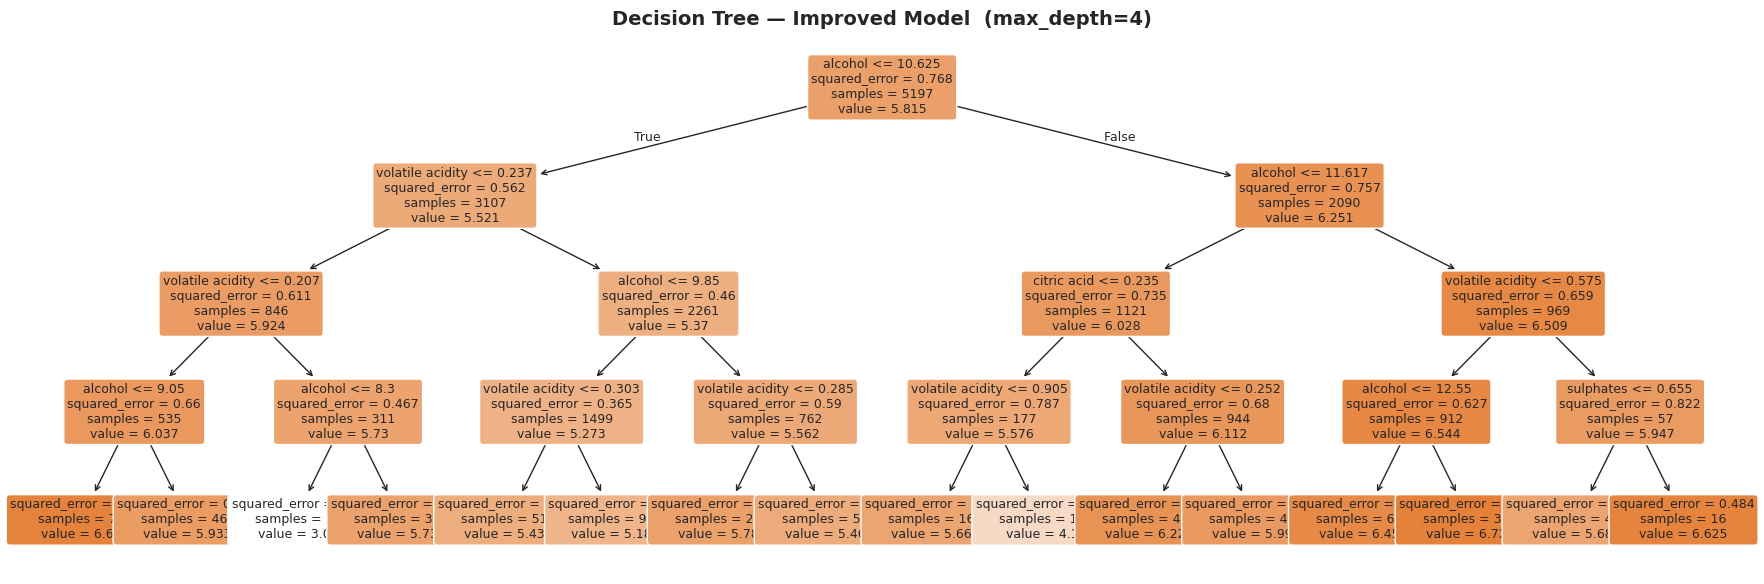

Feature importance:
  alcohol               : 0.7145
  volatile acidity      : 0.2427
  citric acid           : 0.0345
  sulphates             : 0.0082
  wine_type_encoded     : 0.0000
  total sulfur dioxide  : 0.0000
  pH                    : 0.0000


In [ ]:
# ── DECISION TREE VISUALISATION (if using DecisionTreeClassifier or Regressor) ──
# Delete this cell if you are using LogisticRegression or LinearRegression

try:
    class_or_reg = 'Classifier' if hasattr(improved_model, 'predict_proba') else 'Regressor'

    fig, ax = plt.subplots(figsize=(18, 6))
    plot_tree(
        improved_model,
        feature_names=FEATURE_COLS_V2,
        class_names=['Class 0', 'Class 1'] if class_or_reg == 'Classifier' else None,
        filled=True,
        rounded=True,
        ax=ax,
        fontsize=9
    )
    plt.title(f'Decision Tree — Improved Model  (max_depth={improved_model.max_depth})',
              fontweight='bold')
    plt.tight_layout()
    plt.show()

    # Feature importance
    print("Feature importance:")
    for feat, imp in sorted(zip(FEATURE_COLS_V2, improved_model.feature_importances_),
                            key=lambda x: -x[1]):
        print(f"  {feat:<22}: {imp:.4f}")

except Exception as e:
    print(f"Tree visualisation skipped: {e}")

### 6.3 — Improvement Attempt 2 (optional — earns extra marks)

In [ ]:
# ── OPTIONAL: SECOND IMPROVEMENT ATTEMPT ─────────────────────────────
from sklearn.ensemble import RandomForestRegressor

# Use all available chemical features this time
FEATURE_COLS_V3 = ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
                    'chlorides', 'free sulfur dioxide', 'total sulfur dioxide',
                    'density', 'pH', 'sulphates', 'alcohol', 'wine_type_encoded']

df_v3 = df.dropna(subset=FEATURE_COLS_V3 + [TARGET_COL]).copy()
X3    = df_v3[FEATURE_COLS_V3]
y3    = df_v3[TARGET_COL]

X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.2, random_state=42
)

model_v3 = RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42)
model_v3.fit(X3_train, y3_train)
y_pred_v3 = model_v3.predict(X3_test)

mae_v3 = mean_absolute_error(y3_test, y_pred_v3)
r2_v3  = r2_score(y3_test, y_pred_v3)

print("Model Comparison (all attempts)")
print("=" * 55)
print(f"{'Model':<33} {'MAE':>10} {'R²':>8}")
print("-" * 55)
print(f"{'Always-predict-mean':<33} {mae_mean_base:>10.4f} {'0.0000':>8}")
print(f"{'Baseline: LinearRegression':<33} {mae_baseline:>10.4f} {r2_baseline:>8.4f}")
print(f"{'Improved 1: DecisionTreeRegressor':<33} {mae_v2:>10.4f} {r2_v2:>8.4f}")
print(f"{'Improved 2: ' + type(model_v3).__name__:<33} {mae_v3:>10.4f} {r2_v3:>8.4f}")

print()
print("Feature importances (Random Forest):")
importances = sorted(zip(FEATURE_COLS_V3, model_v3.feature_importances_), key=lambda x: -x[1])
for feat, imp in importances:
    print(f"{feat:<25}: {imp:.4f}")

Model Comparison (all attempts)
Model                                    MAE       R²
-------------------------------------------------------
Always-predict-mean                   0.6691   0.0000
Baseline: LinearRegression            0.5785   0.2546
Improved 1: DecisionTreeRegressor     0.5846   0.2361
Improved 2: RandomForestRegressor     0.5176   0.3916

Feature importances (Random Forest):
alcohol                  : 0.3901
volatile acidity         : 0.1618
free sulfur dioxide      : 0.0840
sulphates                : 0.0678
residual sugar           : 0.0542
pH                       : 0.0451
total sulfur dioxide     : 0.0444
chlorides                : 0.0406
fixed acidity            : 0.0384
citric acid              : 0.0380
density                  : 0.0347
wine_type_encoded        : 0.0007


---
## Section 7 — Business Summary

**Member 3 leads this section.**

This is the most important section for the board. The metrics are done.
Now translate them into decisions.

---

### 7.2 — Executive Summary Paragraph

**Complete this paragraph with your actual numbers.** Do not leave any blank.

---

We built a **[regression]** model to answer the following question for CineKenya: **[Can we predit whether a wine will be of high quality using its physicochemical properties?]**.

Using **[alcohol, volatile acidity, sulphates, fixed acidity, citric acid, residual sugar, chlorides, free sulfur dioxide, total sulfur dioxide, density, pH, and wine type]** as inputs, our best model — **[Random Forest Regressor]** — achieved **[Mean Absolute Error (MAE)]: [0.5176]** and **[R² Score]: [0.3916]** on the unseen test set.

This beats the naive baseline of **[MAE = 0.6691 (R² = 0.0000)]** by **[reducing the prediction error by 0.1515 MAE (about 22.6%)]**, meaning the model genuinely learned a pattern rather than guessing.

In practical terms: **[the model predicts wine quality within about half a quality point on average. This can help wineries identify potentially high- or low-quality wines before expert tasting, supporting quality control, pricing, and production decisions while still relying on human experts for final evaluation.]**.

The most important predictor was **[alcohol]**, which suggests that **[alcohol content has the strongest influence on predicting wine quality, indicating that wines with appropriate alcohol levels are generally associated with higher quality ratings.]**.

---

*Your completed paragraph:*

### 7.3 — Three Key Findings for CineKenya

Each finding must be **actionable** — not just what the data shows, but what CineKenya should *do differently* because of it.

Start each finding with "CineKenya should..." or "The model shows that..." and end with a concrete recommendation.

---

**Finding 1:**

*Your answer:*

  WineKenya should focus on alcohol content as the most influential predictor when assessing wine quality, since the Random Forest model identified it as the strongest feature affecting quality predictions.

---

**Finding 2:**

*Your answer:*

The model shows that using multiple physicochemical properties together produces much better predictions than relying on average quality, so the company should use laboratory measurements collectively rather than making decisions based on a single characteristic.
---

**Finding 3:**

*Your answer:*

WineKenya should adopt the Random Forest model instead of simpler linear models, as it achieved the best performance (MAE = 0.5176, R² = 0.3916), demonstrating its ability to capture more complex relationships between wine characteristics and quality.

### 7.4 — Limitations and Next Steps

`[GROUP DECISION]` **Answer in 3 sentences:**

1. What is the main limitation of your model? (What can't it do that the business actually needs?)
2. What additional data or features would most improve it?
3. What would the next iteration look like if you had two more weeks?

*Your answer:*

The main limitation of our model is that it explains only about 39% of the variation in wine quality (R² = 0.3916), meaning many factors influencing quality are not captured in the dataset.

The model would likely improve with additional features such as grape variety, vineyard location, production methods, fermentation process, vintage, storage conditions, and expert sensory evaluation data.

If we had two more weeks, we would perform hyperparameter tuning, test advanced boosting models such as XGBoost or Gradient Boosting, engineer additional features, and use cross-validation to further improve prediction accuracy and model reliability.

---
## Section 8 — Presentation Guide

**All three members contribute. Every member must be able to present every slide.**

Your 5-slide deck must follow this exact structure:

| Slide | Title | What to include |
|-------|-------|----------------|
| 1 | **The Problem** | Business question · Why it matters · What CineKenya would do differently if the model worked |
| 2 | **The Data** | Dataset facts · 1 EDA chart directly relevant to your target · Target variable defined · Features listed |
| 3 | **The Model** | Algorithm choice + 1-sentence justification · The 5-step pipeline · Train/test split sizes |
| 4 | **The Results** | Metric table (baseline vs improved) · Confusion matrix or Actual vs. Predicted chart · 1-sentence interpretation |
| 5 | **The Insight** | 1 main recommendation for CineKenya · 2 supporting findings · 1 next step |

---

### Presentation checklist (complete this before Day 14)

- [ ] Every slide has a clear title and no walls of text
- [ ] Slide 2 chart has title, labelled axes, and 1-sentence caption
- [ ] Slide 4 shows both baseline and improved model metrics — not just the best one
- [ ] Slide 5 recommendation is specific and actionable (not "CineKenya should use more data")
- [ ] Every group member has practiced presenting at least one slide
- [ ] You have timed the presentation — aim for 8 minutes, leave 2 for Q&A

---

### Q&A preparation — questions any member may be asked

Study these as a group. Any of you may be asked any of these on Day 14:

1. *Why did you choose this business question over the other options?*
2. *What does your target variable mean — why did you set the threshold there?*
3. *What is the majority-class baseline and why does it matter?*
4. *Your model has [metric]. What does that number mean in plain English for CineKenya?*
5. *What does a False Negative mean for this problem? What does it cost CineKenya?*
6. *Why did you choose [algorithm] over the alternatives?*
7. *If you had two more weeks, what would you try next?*
8. *[Points at a chart] — what does this chart tell us?*

---
## Submission Checklist

Before uploading to Google Classroom, verify every item below.

### Notebook

- [ ] Group name and all 3 member names at the top of the notebook
- [ ] **Runtime → Restart and run all** — every cell runs without errors
- [ ] All `[GROUP DECISION]` cells filled in — none left as placeholder text
- [ ] **Section 1:** Problem statement complete — business question, target, problem type, 3+ features
- [ ] **Section 2:** At least 2 charts, each with title, axes, and 1-sentence interpretation
- [ ] **Section 2:** EDA summary paragraph written
- [ ] **Section 3:** Target variable created and distribution printed
- [ ] **Section 4:** Train/test split confirmed with row counts printed
- [ ] **Section 5:** Baseline evaluated on TEST set (`y_test`) — not training set
- [ ] **Section 5:** Confusion matrix (classification) or Actual vs. Predicted chart (regression) included
- [ ] **Section 6:** At least one improvement attempted with before/after metric comparison
- [ ] **Section 7:** Executive summary paragraph completed with real numbers
- [ ] **Section 7:** Three actionable findings written
- [ ] **Section 7:** Limitations and next steps written

### Presentation deck

- [ ] 5 slides following the Problem → Data → Model → Results → Insight structure
- [ ] Slide 4 shows metric table comparing baseline vs. improved model
- [ ] Slide 5 contains one concrete, actionable recommendation
- [ ] Submitted as PDF before your group's presentation slot

### Submission deadline

Upload both files to Google Classroom **before** your group is called to present on Day 14.

---

*Questions? Post in the WhatsApp group or ask your instructor at the start of Day 12.*
*Good luck — and remember: the quality of your interpretation matters as much as your metrics.*